In [21]:
import argparse
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as tck
import numpy as np

def load_curve(run_dir: Path, client: str, eval_name: str):
    """Load pre/post metrics for one run directory."""
    xs = []
    ys = []
    rounds = sorted(
        (run_dir / "eval_rounds").glob("round_*"),
        key=lambda p: int(p.name.split("_")[1]),
    )
    for rpath in rounds:
        rid = int(rpath.name.split("_")[1])
        if client == 'server_post_agg':
            fpath = rpath / f"{client}" / "TOFU_EVAL.json"
        else:
            fpath = rpath / f"{client}_{"post_train"}" / "TOFU_EVAL.json"
        if not fpath.exists():
            print(fpath)
            continue
        try:
            payload = json.loads(fpath.read_text())
        except json.JSONDecodeError:
            continue
        if eval_name not in payload:
            continue
        xs.append(rid)
        ys.append(payload[eval_name]["agg_value"])
    return xs, ys

In [22]:
plt.rcParams['text.usetex'] = True
size = (8, 3)

method = "fedperm_only"
retain_split = "retain90"
# fl_method = "FedProx"
fl_method = "FedAvg"
# ul_method = "SimNPO"
ul_method = "GradAscent"
epoch = 1
ce0 = 1
alpha = 1
models = ["Llama-3.2-1B", "Llama-3.2-3B", "Llama-3.1-8B", "Qwen2.5-1.5B", "Qwen2.5-3B", "Qwen2.5-7B"]
me = 2

<>:102: SyntaxWarning: invalid escape sequence '\D'
<>:102: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_372957/2379807845.py:102: SyntaxWarning: invalid escape sequence '\D'
  ax[i//3][i%3].set_ylabel("$\Delta$ FTR")
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


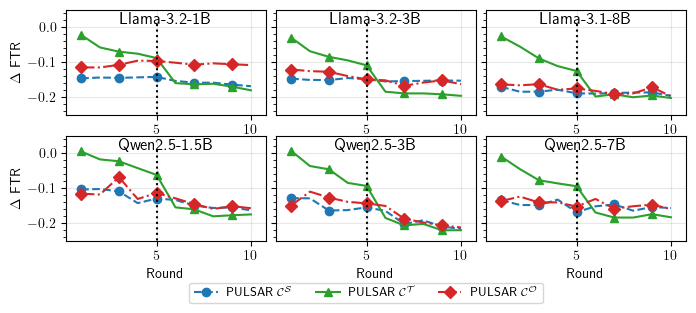

In [23]:
source_client = "client0"
target_client = "client1"
other_client = "client2"
# eval_name = "ra_Q_A_Prob"
# eval_name = "model_utility"
eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

fig, ax = plt.subplots(2, 3, figsize=size, sharex=False, sharey=True)

for i, model in enumerate(models):
    runs = {
        "Finetune": method_root / f"full_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "Retain": method_root / f"retain_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "PULSAR": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_filter1_CE1_Alpha1",
    }

    colors = {
        "source": "#1f77b4",
        "target": "#2ca02c",
        "other": "#d62728"
    }
    linestyles = {"source": "--", "target": "-", "other": "-."}

    for name, path in runs.items():
        if not path.exists():
            print(path)
            continue
        if not (name == "PULSAR"):
            xs, ys = load_curve(path, client=target_client, eval_name=eval_name)
            if name == "Finetune":
                ys2 = np.array(ys[10:])
            elif name == "Retain":
                ys3 = np.array(ys[10:])

        if name == "PULSAR":
            xs, ys = load_curve(path, client=source_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            try:
                ax[i//3][i%3].plot(
                    xs,
                    ys-ys3,
                    label=f"{name} " + r'$\mathcal{C}^\mathcal{S}$',
                    color=colors.get("source"),
                    linestyle=linestyles["source"],
                    marker="o",
                    markevery=me
                )
            except:
                print("failed")
        if name == "PULSAR":
            xs, ys = load_curve(path, client=target_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            try:
                ax[i//3][i%3].plot(
                    xs,
                    ys-ys3,
                    label=f"{name} " + r'$\mathcal{C}^\mathcal{T}$',
                    color=colors.get("target"),
                    linestyle=linestyles["target"],
                    marker="^",
                    markevery=me
                )
            except:
                print("failed")

        # else:
        #     ax.plot(
        #         xs,
        #         ys,
        #         label=f"{name}",
        #         color=colors.get(name),
        #         linestyle=linestyles["target"]
        #     )

        if name == "PULSAR":
            xs, ys = load_curve(path, client=other_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            try:
                ax[i//3][i%3].plot(
                    xs,
                    ys-ys3,
                    label=f"{name} " + r'$\mathcal{C}^\mathcal{O}$',
                    color=colors.get("other"),
                    linestyle=linestyles["other"],
                    marker="D",
                    markevery=me
                )
            except:
                print("failed")
    # ax.vlines(11, 0, 0.22, colors="black", linestyles='dashed')
    ax[i//3][i%3].vlines(5, 0.01, -0.25, colors="black", linestyles=':')
    ax[i//3][i%3].set_ylim(ymin=-0.25, ymax=0.05)
    ax[i//3][i%3].set_xlim(xmin=0.2, xmax=10.8)
    ax[i//3][i%3].yaxis.set_minor_locator(tck.AutoMinorLocator())
    if i//3 == 1:
        ax[i//3][i%3].set_xlabel("Round")
    if i%3 == 0:
        ax[i//3][i%3].set_ylabel("$\Delta$ FTR")
    ax[i//3][i%3].set_title(f"{model}", y=0.9, va="top")
    ax[i//3][i%3].grid(True, alpha=0.3)

handles, labels = ax[i//3][i%3].get_legend_handles_labels()
if labels:
    lgd = plt.legend(handles, labels, loc='center', bbox_to_anchor=(-0.6,-0.5), ncol=3, fontsize=8.5)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.05)
out = f"client_{retain_split}_{fl_method}_{ul_method}_{eval_name}.eps"
plt.savefig(out, dpi=200, bbox_extra_artists=(lgd,), bbox_inches='tight')
# print(f"Saved plot to {out}")
plt.show()

<>:93: SyntaxWarning: invalid escape sequence '\D'
<>:93: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_372957/3802885719.py:93: SyntaxWarning: invalid escape sequence '\D'
  ax[i//3][i%3].set_ylabel("$\Delta$ MU")
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


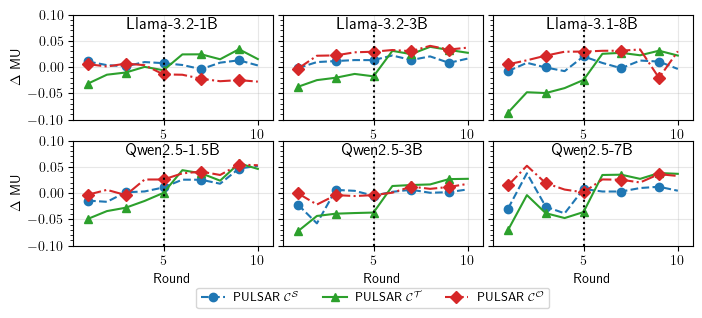

In [20]:
source_client = "client0"
target_client = "client1"
other_client = "client2"
# eval_name = "ra_Q_A_Prob"
eval_name = "model_utility"
# eval_name = "forget_truth_ratio"
# eval_name = "forget_utility"

# method_root = Path("saves") / args.method
method_root = Path("saves/TOFU") / method

fig, ax = plt.subplots(2, 3, figsize=size, sharex=False, sharey=True)

for i, model in enumerate(models):
    runs = {
        "Finetune": method_root / f"full_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "Retain": method_root / f"retain_{fl_method}_{model}-Instruct-lora_{retain_split}",
        "PULSAR": method_root / f"unlearn_{fl_method}_{model}-Instruct-lora_{retain_split}_{ul_method}_filter1_CE1_Alpha1",
    }

    colors = {
        "source": "#1f77b4",
        "target": "#2ca02c",
        "other": "#d62728"
    }
    linestyles = {"source": "--", "target": "-", "other": "-."}

    for name, path in runs.items():
        if not path.exists():
            print(path)
            continue
        if not (name == "PULSAR"):
            xs, ys = load_curve(path, client=target_client, eval_name=eval_name)
            if name == "Finetune":
                ys2 = np.array(ys[10:])
            elif name == "Retain":
                ys3 = np.array(ys[10:])

        if name == "PULSAR":
            xs, ys = load_curve(path, client=source_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            ax[i//3][i%3].plot(
                xs,
                ys-ys2,
                label=f"{name} " + r'$\mathcal{C}^\mathcal{S}$',
                color=colors.get("source"),
                linestyle=linestyles["source"],
                marker="o",
                markevery=me
            )
        if name == "PULSAR":
            xs, ys = load_curve(path, client=target_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            ax[i//3][i%3].plot(
                xs,
                ys-ys2,
                label=f"{name} " + r'$\mathcal{C}^\mathcal{T}$',
                color=colors.get("target"),
                linestyle=linestyles["target"],
                marker="^",
                markevery=me
            )

        # else:
        #     ax.plot(
        #         xs,
        #         ys,
        #         label=f"{name}",
        #         color=colors.get(name),
        #         linestyle=linestyles["target"]
        #     )

        if name == "PULSAR":
            xs, ys = load_curve(path, client=other_client, eval_name=eval_name)
            # xs = [i+10 for i in xs]
            ax[i//3][i%3].plot(
                xs,
                ys-ys2,
                label=f"{name} " + r'$\mathcal{C}^\mathcal{O}$',
                color=colors.get("other"),
                linestyle=linestyles["other"],
                marker="D",
                markevery=me
            )
    # ax.vlines(11, 0, 0.22, colors="black", linestyles='dashed')
    ax[i//3][i%3].vlines(5, -0.1, 0.07, colors="black", linestyles=':')
    ax[i//3][i%3].set_ylim(ymin=-0.1, ymax=0.1)
    ax[i//3][i%3].set_xlim(xmin=0.2, xmax=10.8)
    ax[i//3][i%3].yaxis.set_minor_locator(tck.AutoMinorLocator())
    if i//3 == 1:
        ax[i//3][i%3].set_xlabel("Round")
    if i%3 == 0:
        ax[i//3][i%3].set_ylabel("$\Delta$ MU")
    ax[i//3][i%3].set_title(f"{model}", y=0.9, va="top")
    ax[i//3][i%3].grid(True, alpha=0.3)
    ax[i//3][i%3].set_yticks([-0.1, -0.05, 0, 0.05, 0.1])

handles, labels = ax[i//3][i%3].get_legend_handles_labels()
if labels:
    lgd = plt.legend(handles, labels, loc='center', bbox_to_anchor=(-0.6,-0.5), ncol=3, fontsize=8.5)
# plt.tight_layout()
plt.subplots_adjust(wspace=0.05)
out = f"client_{retain_split}_{fl_method}_{ul_method}_{eval_name}.eps"
plt.savefig(out, dpi=200, bbox_extra_artists=(lgd,), bbox_inches='tight')
# print(f"Saved plot to {out}")
plt.show()